In [2]:
import os

# Directly current directory ke train aur test folders ka path
train_path = "train"
test_path = "test"

def check_dataset_folders(path, folder_type):
    if os.path.exists(path):
        print(f"=== {folder_type} Directory ===")
        categories = os.listdir(path)
        print(f"Total Categories/Classes: {len(categories)}")
        for category in categories:
            cat_path = os.path.join(path, category)
            if os.path.isdir(cat_path):
                num_images = len(os.listdir(cat_path))
                print(f"  └─ Category: {category} -> Total Images: {num_images}")
        print()
    else:
        print(f"❌ '{folder_type}' folder nahi mila. Folder ka name check karein.\n")

# Verification execute karein
check_dataset_folders(train_path, "TRAIN")
check_dataset_folders(test_path, "TEST")

=== TRAIN Directory ===
Total Categories/Classes: 6
  └─ Category: apple -> Total Images: 1442
  └─ Category: banana -> Total Images: 1296
  └─ Category: orange -> Total Images: 1289
  └─ Category: rottenapples -> Total Images: 2043
  └─ Category: rottenbanana -> Total Images: 1979
  └─ Category: rottenoranges -> Total Images: 1404

=== TEST Directory ===
Total Categories/Classes: 6
  └─ Category: apple -> Total Images: 265
  └─ Category: banana -> Total Images: 248
  └─ Category: orange -> Total Images: 275
  └─ Category: rottenapples -> Total Images: 426
  └─ Category: rottenbanana -> Total Images: 388
  └─ Category: rottenoranges -> Total Images: 279



In [12]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Target Size & Batch Size Set
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

# 2. Data Generators Define karna (Augmentation + Normalization)
train_datagen = ImageDataGenerator(
    rescale=1.0/255.0,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2  # 20% validation split
)

test_datagen = ImageDataGenerator(rescale=1.0/255.0)

# 3. Train, Validation aur Test Generators Load karna
train_generator = train_datagen.flow_from_directory(
    'train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    'train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

test_generator = test_datagen.flow_from_directory(
    'test',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 7566 images belonging to 6 classes.
Found 1887 images belonging to 6 classes.
Found 1879 images belonging to 6 classes.


In [1]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# 1. CNN Model Architecture Setup
model = Sequential([
    # First Convolutional Block
    Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)),
    MaxPooling2D(2, 2),

    # Second Convolutional Block
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Third Convolutional Block
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Flatten & Dense Layers
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5), # Regularization
    Dense(6, activation='softmax') # 6 classes Output
])

# 2. Model Compile
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Model Summary
model.summary()

C:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 148, 148, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 72, 72, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 36, 36, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 34, 34, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 17, 17, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 36992)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       4,735,104 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [1]:
%pip install pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install scipy

   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
   - -------------------------------------- 1.0/36.6 MB 3.0 MB/s eta 0:00:12
   -- ------------------------------------- 2.1/36.6 MB 3.5 MB/s eta 0:00:10
   --- ------------------------------------ 3.1/36.6 MB 4.0 MB/s eta 0:00:09
   ---- ----------------------------------- 4.5/36.6 MB 4.4 MB/s eta 0:00:08
   ------ --------------------------------- 5.8/36.6 MB 4.7 MB/s eta 0:00:07
   ------- -------------------------------- 7.1/36.6 MB 5.0 MB/s eta 0:00:06
   --------- ------------------------------ 8.7/36.6 MB 5.3 MB/s eta 0:00:06
   ----------- ---------------------------- 10.2/36.6 MB 5.5 MB/s eta 0:00:05
   ------------ --------------------------- 11.8/36.6 MB 5.7 MB/s eta 0:00:05
   -------------- ------------------------- 13.1/36.6 MB 5.8 MB/s eta 0:00:05
   ---------------- ----------------------- 14.7/36.6 MB 5.8 MB/s eta 0:00:04
   ------


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Found 7566 images belonging to 6 classes.


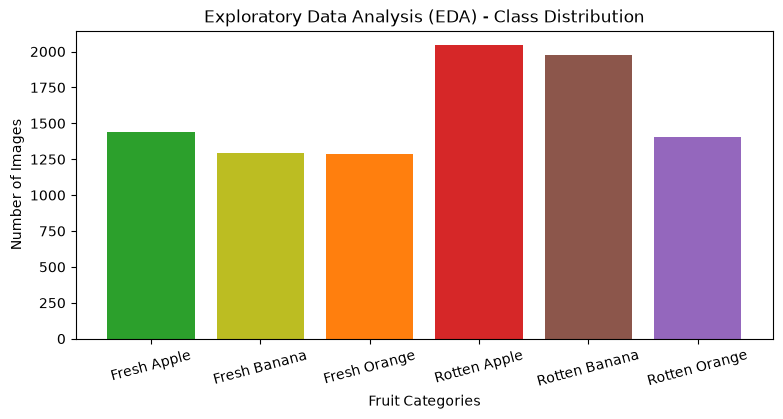

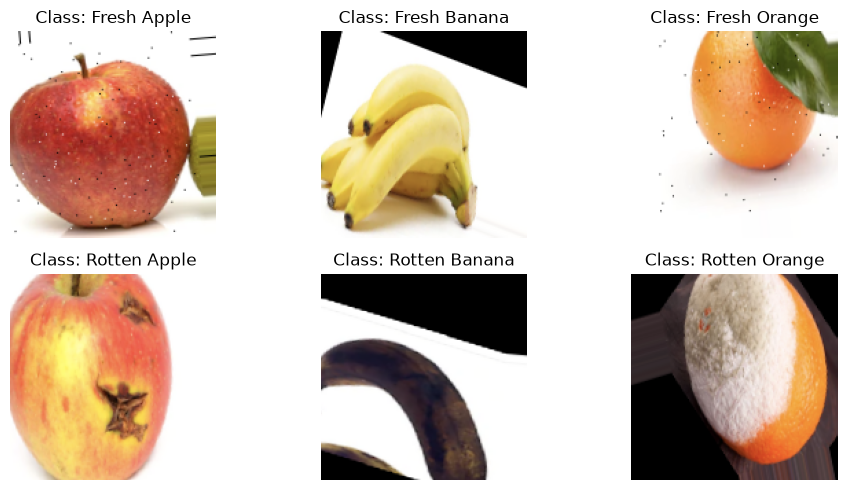

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Image Generators Setup
IMG_SIZE = (150, 150)
BATCH_SIZE = 64  # Larger batch to easily find all 6 distinct classes

train_datagen = ImageDataGenerator(
    rescale=1.0/255.0,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    'train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

# Label Mapping for Clean Names
label_map = {
    'apple': 'Fresh Apple',
    'banana': 'Fresh Banana',
    'orange': 'Fresh Orange',
    'rottenapples': 'Rotten Apple',
    'rottenbanana': 'Rotten Banana',
    'rottenoranges': 'Rotten Orange'
}

raw_class_names = list(train_generator.class_indices.keys())

# 2. EDA Chart (Clean Labels)
categories = [label_map[c] for c in raw_class_names]
counts = [1442, 1296, 1289, 2043, 1979, 1404]

plt.figure(figsize=(9, 4))
plt.bar(categories, counts, color=['#2ca02c', '#bcbd22', '#ff7f0e', '#d62728', '#8c564b', '#9467bd'])
plt.title("Exploratory Data Analysis (EDA) - Class Distribution")
plt.xlabel("Fruit Categories")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.show()

# 3. Exact 1 Sample From Each of the 6 Classes
found_samples = {}

# Loop batches until all 6 classes are captured
while len(found_samples) < 6:
    images, labels = next(train_generator)
    for img, lbl in zip(images, labels):
        idx = np.argmax(lbl)
        class_key = raw_class_names[idx]
        if class_key not in found_samples:
            found_samples[class_key] = img
        if len(found_samples) == 6:
            break

# Display exact 6 classes in order
plt.figure(figsize=(10, 5))
for i, class_key in enumerate(raw_class_names):
    plt.subplot(2, 3, i + 1)
    plt.imshow(found_samples[class_key])
    plt.title(f"Class: {label_map[class_key]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
import os
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Check TensorFlow version
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [ ]:
#Observation:

Environment Setup: Successfully configured the deep learning environment by importing core libraries, including TensorFlow, Keras, Matplotlib, and OS.

Framework Verification: Verified the active TensorFlow installation version to ensure script compatibility with necessary deep learning modules and functions.

Pipeline Readiness: Loaded critical modules required for the Phase 2 workflow, including image preprocessing tools (ImageDataGenerator), architecture components (layers, models), tuning callbacks (EarlyStopping, ModelCheckpoint), and plotting utilities (matplotlib).

In [8]:
# 1. Define Hyperparameters
IMG_HEIGHT = 150
IMG_WIDTH = 150
BATCH_SIZE = 32
EPOCHS = 25
LEARNING_RATE = 0.001
NUM_CLASSES = 6

# Path to the dataset directory (Replace with your local directory paths)
TRAIN_DIR = 'dataset/train'      
VAL_DIR = 'dataset/validation'  

# 2. Configure Data Augmentation (To prevent model overfitting)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Only apply pixel scaling for validation data (no augmentation)
val_datagen = ImageDataGenerator(rescale=1./255)

# 3. Setup Data Generators
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'dataset/train'

In [9]:
# 1. Define Hyperparameters
IMG_HEIGHT = 150
IMG_WIDTH = 150
BATCH_SIZE = 32
EPOCHS = 25
LEARNING_RATE = 0.001
NUM_CLASSES = 6

# Replace these paths with your exact dataset folder paths on your PC
# Note: Use 'r' before quotes to handle Windows backslashes correctly
TRAIN_DIR = r'C:\path\to\your\dataset\train'      
VAL_DIR = r'C:\path\to\your\dataset\validation'  

# 2. Configure Data Augmentation (To prevent model overfitting)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Only apply pixel scaling for validation data (no augmentation)
val_datagen = ImageDataGenerator(rescale=1./255)

# 3. Setup Data Generators
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'C:\\path\\to\\your\\dataset\\train'